For stability, the first run is capped at 100,000 events per file; increase the cap only after a successful run.

Inputs: all 29 candidate branches

Physics selection: exactly two selected, isolated leptons (electron/muon), leading lepton pT>25 GeV, subleading pT>13 GeV, opposite-sign pair, mll>12 GeV, and Puppi missing transverse momentum pT^miss>20 GeV.

Models: XGBoost primary classifier, Random Forest baseline, optional 1D CNN comparison.

Evaluation: dedicated *-test.root files when all are available; otherwise a stratified held-out split from the training files, clearly labelled as a fallback.

important: The code uses the highest-pT object within each Electron/Muon/Jet collection to turn jagged object branches into one scalar per event. The physics selection is applied to the combined electron+muon collections before the ML table is built. The 29 model inputs are the supplied branches; the selection-derived helper values are not added as extra inputs

--------

Our goal is to develop a machine-learning classifier that separates simulated Higgs signal events from the WW, Top, and DY backgrounds in the H→WW dilepton channel.

We first **read the ROOT samples** in chunks and **apply a baseline event selection requiring exactly two selected electrons or muons, opposite charge, suitable lepton transverse momentum, dilepton invariant mass above 12 GeV, and missing transverse momentum above 20 GeV**.

We then construct an **event-level dataset using 29 candidate features**, including lepton and jet kinematics, missing transverse momentum, and derived quantities such as the dilepton invariant mass and transverse-mass variables.

Our primary model is **XGBoost**, which uses gradient-boosted decision trees. On the capped evaluation sample, it achieves a **ROC-AUC of 0.9336**, compared with **0.9301 for our Random Forest baseline**. This indicates promising signal–background ranking performance on the sample evaluated.

We also inspect train-versus-test performance, score distributions, and feature importance to understand the model's behaviour. The dilepton invariant mass is particularly important in our current analysis.

There are **limitations** we still need to address. We have used at most 100,000 input events per file, and the Top sample has an unexpectedly low selected yield. Our **next steps are to investigate the Top cutflow, validate the selection and features, and perform systematic hyperparameter tuning** using a validation sample while keeping the dedicated test files untouched.

# Import and configuration

In [2]:
from pathlib import Path
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import uproot
import awkward as ak

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    roc_auc_score, accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay, roc_curve
)
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance

RANDOM_STATE = 42
DATA_DIR = Path("/data/bvcoe2026/CMS-OD/samples")
MAX_EVENTS_PER_FILE = 100_000  # HARD LIMIT per file for a safer first run; use None only after this works and RAM is sufficient.

PROCESS_FILES = {
    "Higgs": {"label": 1},
    "WW":    {"label": 0},
    "Top":   {"label": 0},
    "DY":    {"label": 0},
}

# All 29 candidate features. Every feature is checked against every sample file.
CANDIDATE_FEATURES = [
    "Electron_pt", "Electron_eta", "Electron_phi", "Electron_mass",
    "Electron_charge", "Electron_mvaFall17V2Iso_WP90",
    "Muon_pt", "Muon_eta", "Muon_phi", "Muon_mass",
    "Muon_charge", "Muon_tightId", "Muon_pfRelIso04_all",
    "Jet_pt", "Jet_eta", "Jet_phi", "Jet_mass", "Jet_btagDeepFlavB",
    "Jet_jetId", "Jet_puId",
    "PuppiMET_pt", "PuppiMET_phi",
    "mll", "ptll", "dphill", "mth", "mtw2", "mjj", "nJet"
]
assert len(CANDIDATE_FEATURES) == 29

# Explicit baseline H->WW dilepton selection (GeV for pT and invariant mass).
LEPTON_LOOSE_PT_MIN = 10.0
LEADING_LEPTON_PT_MIN = 25.0
SUBLEADING_LEPTON_PT_MIN = 13.0
ELECTRON_ABS_ETA_MAX = 2.5
MUON_ABS_ETA_MAX = 2.4
MUON_REL_ISO_MAX = 0.15
DILEPTON_MASS_MIN = 12.0
PUPPI_MET_PT_MIN = 20.0

print("uproot:", uproot.__version__)
print("awkward:", ak.__version__)
print("Sample directory exists:", DATA_DIR.is_dir())
print("Number of candidate features:", len(CANDIDATE_FEATURES))

uproot: 5.7.7
awkward: 2.14.0
Sample directory exists: True
Number of candidate features: 29


two selected leptons, opposite charge, a dilepton invariant mass above 12 GeV and missing transverse momentum above 20 GeV.

# Locate and validate the files

In [3]:
if not DATA_DIR.is_dir():
    raise FileNotFoundError(
        f"Sample directory not found: {DATA_DIR}. Run this notebook in the HSF environment that contains the samples."
    )

all_root_files = sorted(DATA_DIR.glob("*.root"))
print(f"Found {len(all_root_files)} ROOT files:")
for p in all_root_files:
    print(" -", p.name)

def locate_sample(process, split):
    expected = f"{process}-{split}.root".lower()
    matches = [p for p in all_root_files if p.name.lower() == expected]
    return matches[0] if matches else None

sample_paths = {
    split: {process: locate_sample(process, split) for process in PROCESS_FILES}
    for split in ("train", "test")
}

for split, mapping in sample_paths.items():
    print(f"\n{split.upper()} files:")
    for process, path in mapping.items():
        print(f"  {process:6s}: {path.name if path else 'MISSING'}")

if not all(sample_paths["train"].values()):
    raise FileNotFoundError("One or more required training files are missing. Check the printed filenames and update locate_sample().")

USE_FILE_TEST_SET = all(sample_paths["test"].values())
if not USE_FILE_TEST_SET:
    print("\nWARNING: not all dedicated test files exist. A stratified held-out split will be made from the available training files.")

Found 8 ROOT files:
 - DY-test.root
 - DY-train.root
 - Higgs-test.root
 - Higgs-train.root
 - Top-test.root
 - Top-train.root
 - WW-test.root
 - WW-train.root

TRAIN files:
  Higgs : Higgs-train.root
  WW    : WW-train.root
  Top   : Top-train.root
  DY    : DY-train.root

TEST files:
  Higgs : Higgs-test.root
  WW    : WW-test.root
  Top   : Top-test.root
  DY    : DY-test.root


# Safe scalar conversion and physics selection

In [4]:
def _is_jagged(array):
    """Return True if an Awkward array has a per-event collection axis."""
    try:
        ak.num(array, axis=1)
        return True
    except (ValueError, TypeError, IndexError):
        return False

def as_jagged(array):
    """Ensure an event-wise collection is jagged (one list per event)."""
    if _is_jagged(array):
        return array
    values = ak.to_list(array)
    return ak.Array([[] if value is None else [value] for value in values])

def safe_bool(array):
    return ak.fill_none(array, False)

def event_scalar(array):
    """Convert a scalar-per-event Awkward array to a NumPy float array."""
    values = ak.to_numpy(ak.fill_none(array, np.nan))
    return np.asarray(values, dtype=float)

def leading_object_values(arrays, branch_name):
    """Return the highest-pT object's value for object branches, or event scalar."""
    arr = arrays[branch_name]
    if branch_name.startswith(("Electron_", "Muon_", "Jet_")) and _is_jagged(arr):
        prefix = branch_name.split("_", 1)[0]
        pt_branch = f"{prefix}_pt"
        if pt_branch not in arrays.fields:
            raise KeyError(f"Cannot sort {branch_name}: missing {pt_branch}.")
        pt = arrays[pt_branch]
        order = ak.argsort(pt, axis=1, ascending=False)
        arr = arr[order]
        arr = ak.firsts(arr, axis=1)
        arr = ak.fill_none(arr, np.nan)
    return event_scalar(arr)

def make_selection(arrays):
    """Return a sequential cutflow and a boolean mask for a baseline H->WW dilepton selection."""
    # Collections are used in full here; all per-object fields must remain aligned.
    e_pt = as_jagged(arrays["Electron_pt"])
    e_eta = as_jagged(arrays["Electron_eta"])
    e_charge = as_jagged(arrays["Electron_charge"])
    e_id = as_jagged(arrays["Electron_mvaFall17V2Iso_WP90"])

    m_pt = as_jagged(arrays["Muon_pt"])
    m_eta = as_jagged(arrays["Muon_eta"])
    m_charge = as_jagged(arrays["Muon_charge"])
    m_id = as_jagged(arrays["Muon_tightId"])
    m_iso = as_jagged(arrays["Muon_pfRelIso04_all"])

    # Baseline selected leptons: ID + acceptance + loose pT; the final pT thresholds are applied to the pair.
    e_good = safe_bool((e_pt > LEPTON_LOOSE_PT_MIN) & (abs(e_eta) < ELECTRON_ABS_ETA_MAX) & (e_id == 1))
    m_good = safe_bool((m_pt > LEPTON_LOOSE_PT_MIN) & (abs(m_eta) < MUON_ABS_ETA_MAX) & (m_id == 1) & (m_iso < MUON_REL_ISO_MAX))

    selected_pt = ak.concatenate([e_pt[e_good], m_pt[m_good]], axis=1)
    selected_charge = ak.concatenate([e_charge[e_good], m_charge[m_good]], axis=1)
    order = ak.argsort(selected_pt, axis=1, ascending=False)
    selected_pt = selected_pt[order]
    selected_charge = selected_charge[order]

    n_selected = ak.num(selected_pt, axis=1)
    lead_pt = event_scalar(ak.fill_none(ak.firsts(selected_pt), np.nan))
    sublead_pt = event_scalar(ak.fill_none(ak.firsts(selected_pt[:, 1:]), np.nan))
    lead_charge = event_scalar(ak.fill_none(ak.firsts(selected_charge), np.nan))
    sublead_charge = event_scalar(ak.fill_none(ak.firsts(selected_charge[:, 1:]), np.nan))
    opposite_sign = (lead_charge * sublead_charge) < 0

    mll = event_scalar(arrays["mll"])
    met_pt = event_scalar(arrays["PuppiMET_pt"])
    n_events = len(mll)
    mask = np.ones(n_events, dtype=bool)
    cutflow = [("All events", int(mask.sum()))]

    cuts = [
        ("Exactly two selected e/μ", n_selected == 2),
        (f"Leading lepton pT > {LEADING_LEPTON_PT_MIN:g} GeV", lead_pt > LEADING_LEPTON_PT_MIN),
        (f"Subleading lepton pT > {SUBLEADING_LEPTON_PT_MIN:g} GeV", sublead_pt > SUBLEADING_LEPTON_PT_MIN),
        ("Opposite-sign dilepton pair", opposite_sign),
        (f"mll > {DILEPTON_MASS_MIN:g} GeV", np.isfinite(mll) & (mll > DILEPTON_MASS_MIN)),
        (f"PuppiMET pT > {PUPPI_MET_PT_MIN:g} GeV", np.isfinite(met_pt) & (met_pt > PUPPI_MET_PT_MIN)),
    ]
    for name, condition in cuts:
        mask &= np.asarray(condition, dtype=bool)
        cutflow.append((name, int(mask.sum())))
    return mask, cutflow

def read_sample(file_path, process, split, max_events=MAX_EVENTS_PER_FILE, step_size=25000):
    """Read a ROOT/RNTuple sample in chunks to avoid loading millions of events at once.

    Physics selection is applied chunk-by-chunk. Only selected events are converted
    to a pandas DataFrame, keeping peak memory substantially lower.
    """
    frame_parts = []
    total_read = 0
    total_selected = 0
    cutflow_names = None
    cutflow_totals = None

    with uproot.open(file_path) as root_file:
        if "Events" not in root_file:
            raise KeyError(
                f"No 'Events' RNTuple/tree in {file_path.name}. Keys: {root_file.keys()}"
            )

        events = root_file["Events"]
        available = set(events.keys())
        missing = [name for name in CANDIDATE_FEATURES if name not in available]
        if missing:
            raise KeyError(
                f"{file_path.name} is missing {len(missing)} required features: {missing}"
            )

        n_entries = int(events.num_entries)
        entry_stop = n_entries if max_events is None else min(n_entries, int(max_events))

        for arrays in events.iterate(
            expressions=CANDIDATE_FEATURES,
            entry_start=0,
            entry_stop=entry_stop,
            step_size=step_size,
            library="ak",
        ):
            n_chunk = len(arrays)
            total_read += n_chunk
            selection_mask, chunk_cutflow = make_selection(arrays)

            if cutflow_names is None:
                cutflow_names = [name for name, _ in chunk_cutflow]
                cutflow_totals = np.zeros(len(chunk_cutflow), dtype=np.int64)

            if [name for name, _ in chunk_cutflow] != cutflow_names:
                raise RuntimeError("Cutflow labels changed between chunks.")

            cutflow_totals += np.asarray([count for _, count in chunk_cutflow], dtype=np.int64)
            selected_count = int(np.count_nonzero(selection_mask))
            total_selected += selected_count

            if selected_count == 0:
                del arrays, selection_mask
                continue

            # Filter the Awkward record BEFORE converting to NumPy/Pandas.
            selected_arrays = arrays[selection_mask]
            data = {
                name: leading_object_values(selected_arrays, name)
                for name in CANDIDATE_FEATURES
            }
            part = pd.DataFrame(data)
            part = part.replace([np.inf, -np.inf], np.nan)
            part = part.mask(part <= -900, np.nan)
            part["process"] = process
            part["label"] = PROCESS_FILES[process]["label"]
            part["split"] = split
            frame_parts.append(part)

            del arrays, selection_mask, selected_arrays, data, part

    if frame_parts:
        frame = pd.concat(frame_parts, ignore_index=True, sort=False, copy=False)
        del frame_parts
    else:
        frame = pd.DataFrame(columns=CANDIDATE_FEATURES + ["process", "label", "split"])

    print(
        f"\n{file_path.name}: read {total_read:,}; "
        f"selected {total_selected:,} ({total_selected / max(total_read, 1):.1%})"
    )

    if cutflow_names is not None:
        cutflow_frame = pd.DataFrame({
            "Selection": cutflow_names,
            "Events remaining": cutflow_totals,
        })
        cutflow_frame["Efficiency vs previous"] = cutflow_frame["Events remaining"].div(
            cutflow_frame["Events remaining"].shift(1).replace(0, np.nan)
        )
        display(cutflow_frame)

    return frame


# Read samples and build the eevent tables

The selection is applied separately to each process and split, and the per-file cutflow is printed.

In [5]:
# Memory-safe dataset assembly.
# MAX_EVENTS_PER_FILE (Cell 2) is a hard cap per file; chunking also limits per-read memory.
import gc


def load_split(split_name):
    frames = []
    for process, path in sample_paths[split_name].items():
        print(f"Loading {process} {split_name} sample: {path.name}")
        frame = read_sample(path, process, split_name)
        frames.append(frame)
        # Release local references to temporary objects before loading next sample.
        gc.collect()
    if not frames:
        raise ValueError(f"No files were loaded for split {split_name!r}.")
    combined = pd.concat(frames, ignore_index=True, sort=False, copy=False)
    del frames
    gc.collect()
    return combined


train_all = load_split("train")

if USE_FILE_TEST_SET:
    test_df = load_split("test")
    train_df = train_all  # avoid a full copy of the training dataframe
    evaluation_source = "dedicated test files (capped events per file)"
else:
    train_df, test_df = train_test_split(
        train_all,
        test_size=0.25,
        random_state=RANDOM_STATE,
        stratify=train_all["label"],
    )
    train_df = train_df.reset_index(drop=True)
    test_df = test_df.reset_index(drop=True)
    evaluation_source = "stratified holdout from capped training samples"
    del train_all
    gc.collect()

feature_cols = CANDIDATE_FEATURES.copy()
if len(feature_cols) != 29:
    raise ValueError(f"Expected 29 features; got {len(feature_cols)}.")

for col in feature_cols:
    if col not in train_df.columns or col not in test_df.columns:
        raise KeyError(f"Feature {col!r} is missing from training or evaluation data.")

for name, frame in [("training", train_df), ("evaluation", test_df)]:
    if frame.empty:
        raise ValueError(f"The {name} sample is empty after selection. Check the cutflow.")
    if frame["label"].nunique() < 2:
        raise ValueError(
            f"The {name} sample contains only one class after selection. "
            "Inspect the per-process cutflows and sample definitions."
        )

print("\nFeature count:", len(feature_cols))
print("Feature names:", feature_cols)
print("Training rows:", f"{len(train_df):,}", "| Evaluation rows:", f"{len(test_df):,}")
print("Evaluation source:", evaluation_source)
print("\nTraining counts by process:")
display(train_df.groupby(["process", "label"]).size().rename("events").reset_index())
print("Evaluation counts by process:")
display(test_df.groupby(["process", "label"]).size().rename("events").reset_index())

print(
    "\nSafer first run is configured for up to",
    MAX_EVENTS_PER_FILE,
    "events per file. This is a capped validation subset, not a full-statistics result."
)


Loading Higgs train sample: Higgs-train.root

Higgs-train.root: read 100,000; selected 12,062 (12.1%)


/tmp/ipykernel_308/3615333456.py:161: Pandas4Warning: The copy keyword is deprecated and will be removed in a future version. Copy-on-Write is active in pandas since 3.0 which utilizes a lazy copy mechanism that defers copies until necessary. Use .copy() to make an eager copy if necessary.
  frame = pd.concat(frame_parts, ignore_index=True, sort=False, copy=False)


,Selection,Events remaining,Efficiency vs previous
0,All events,100000,NaN
1,Exactly two selected e/μ,19993,0.199930
2,Leading lepton pT > 25 GeV,16877,0.844145
3,Subleading lepton pT > 13 GeV,14347,0.850092
4,Opposite-sign dilepton pair,14272,0.994772
5,mll > 12 GeV,13412,0.939742
6,PuppiMET pT > 20 GeV,12062,0.899344


Loading WW train sample: WW-train.root

WW-train.root: read 100,000; selected 17,450 (17.4%)


/tmp/ipykernel_308/3615333456.py:161: Pandas4Warning: The copy keyword is deprecated and will be removed in a future version. Copy-on-Write is active in pandas since 3.0 which utilizes a lazy copy mechanism that defers copies until necessary. Use .copy() to make an eager copy if necessary.
  frame = pd.concat(frame_parts, ignore_index=True, sort=False, copy=False)


...

/tmp/ipykernel_308/1645576506.py:16: Pandas4Warning: The copy keyword is deprecated and will be removed in a future version. Copy-on-Write is active in pandas since 3.0 which utilizes a lazy copy mechanism that defers copies until necessary. Use .copy() to make an eager copy if necessary.
  combined = pd.concat(frames, ignore_index=True, sort=False, copy=False)


,process,label,events
0,DY,0,9001
1,Higgs,1,12062
2,Top,0,67
3,WW,0,17450


Evaluation counts by process:


,process,label,events
0,DY,0,8714
1,Higgs,1,11947
2,Top,0,58
3,WW,0,17885



Safer first run is configured for up to 100000 events per file. This is a capped validation subset, not a full-statistics result.


# Missing value and class-balance diagnostics

Missing-value diagnostics: Are some of the model's input features missing, undefined, or invalid?

Class-balance diagnostics: How many Higgs signal and background events do we have, and is one class dominating the training or evaluation sample?

,missing_fraction_train,missing_fraction_eval,unique_values_train
Electron_pt,0.290306,0.287224,27358
Electron_eta,0.290306,0.287224,18205
Electron_phi,0.290306,0.287224,17055
Electron_mass,0.290306,0.287224,10246
Electron_charge,0.290306,0.287224,2
Electron_mvaFall17V2Iso_WP90,0.290306,0.287224,2
Muon_pt,0.255184,0.257616,28712
Muon_eta,0.255184,0.257616,18580
Muon_phi,0.255184,0.257616,17391
Muon_mass,0.255184,0.257616,2


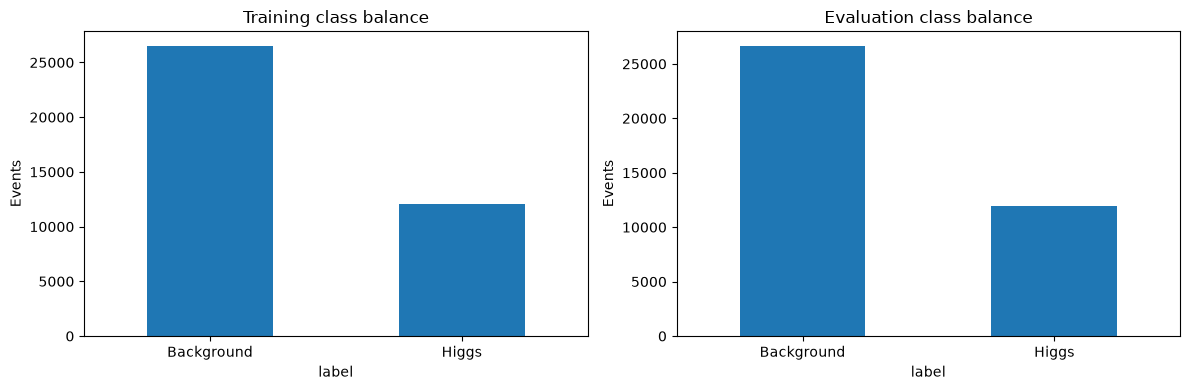

In [6]:
missing_summary = pd.DataFrame({
    "missing_fraction_train": train_df[feature_cols].isna().mean(),
    "missing_fraction_eval": test_df[feature_cols].isna().mean(),
    "unique_values_train": train_df[feature_cols].nunique(dropna=True),
}).sort_values("missing_fraction_train", ascending=False)
display(missing_summary)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
train_df["label"].value_counts().sort_index().rename(index={0: "Background", 1: "Higgs"}).plot(kind="bar", ax=axes[0])
axes[0].set_title("Training class balance")
axes[0].set_ylabel("Events")
axes[0].tick_params(axis="x", rotation=0)
test_df["label"].value_counts().sort_index().rename(index={0: "Background", 1: "Higgs"}).plot(kind="bar", ax=axes[1])
axes[1].set_title("Evaluation class balance")
axes[1].set_ylabel("Events")
axes[1].tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

# Build model matriics

The model receives exactly the 29 requested branches. process, split, and label are bookkeeping/target columns and are excluded from the inputs. XGBoost can handle NaNs directly.

In [7]:
X_train = train_df[feature_cols].replace([np.inf, -np.inf], np.nan).copy()
y_train = train_df["label"].astype(int).to_numpy()
X_test = test_df[feature_cols].replace([np.inf, -np.inf], np.nan).copy()
y_test = test_df["label"].astype(int).to_numpy()

print("X_train:", X_train.shape, "| y_train:", y_train.shape)
print("X_eval: ", X_test.shape, "| y_eval: ", y_test.shape)
print("All 29 input columns present:", X_train.shape[1] == 29 and X_test.shape[1] == 29)
print("Training Higgs fraction:", round(float(y_train.mean()), 4))
print("Evaluation Higgs fraction:", round(float(y_test.mean()), 4))

X_train: (38580, 29) | y_train: (38580,)
X_eval:  (38604, 29) | y_eval:  (38604,)
All 29 input columns present: True
Training Higgs fraction: 0.3126
Evaluation Higgs fraction: 0.3095


# Try XGBoost

In [38]:
try:
    from xgboost import XGBClassifier
except ImportError as exc:
    raise ImportError("XGBoost is not installed. In a separate notebook cell run `%pip install xgboost`, restart the kernel, then rerun.") from exc

xgb_model = XGBClassifier(
    n_estimators=500,     #no. of boosting trees
    max_depth=4,          #depth of each tree
    learning_rate=0.04,
    subsample=0.85,       #each tree uses random 85% sample of training rows
    colsample_bytree=0.9, #each tree uses random 90% of input features
    objective="binary:logistic",
    eval_metric="auc",
    tree_method="hist",
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

# xgb_model = XGBClassifier(
#     n_estimators=700,
#     max_depth=5,
#     learning_rate=0.03,
#     subsample=0.85,
#     colsample_bytree=0.75,
#     objective="binary:logistic",
#     eval_metric="auc",
#     tree_method="hist",
#     random_state=RANDOM_STATE,
#     n_jobs=-1,
# )

xgb_model.fit(X_train, y_train)
xgb_prob = xgb_model.predict_proba(X_test)[:, 1]
xgb_pred = (xgb_prob >= 0.5).astype(int)
xgb_auc = roc_auc_score(y_test, xgb_prob)

print(f"XGBoost ROC-AUC: {xgb_auc:.4f}")
print(f"Accuracy at threshold 0.5: {accuracy_score(y_test, xgb_pred):.4f}")
print(f"Precision: {precision_score(y_test, xgb_pred, zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_test, xgb_pred, zero_division=0):.4f}")
print(f"F1 score:  {f1_score(y_test, xgb_pred, zero_division=0):.4f}")
print("\nClassification report:")
print(classification_report(y_test, xgb_pred, target_names=["Background", "Higgs"], zero_division=0))

XGBoost ROC-AUC: 0.9336
Accuracy at threshold 0.5: 0.8634
Precision: 0.7405
Recall:    0.8598
F1 score:  0.7957

Classification report:
              precision    recall  f1-score   support

  Background       0.93      0.86      0.90     26657
       Higgs       0.74      0.86      0.80     11947

    accuracy                           0.86     38604
   macro avg       0.84      0.86      0.85     38604
weighted avg       0.87      0.86      0.87     38604



**what does these numbers mean??**

ROC (Performance on events used to fit the model) - the classifier shows good separation between signal and background on this evaluation sample

accuracy - 86.34% of test events were classified correctly at the chosen threshold of 0.5

signal recall - model correctly identifies about this much of higgs-lavbelled test events

precision - 74.05 of the events predicted top be higgs signal, about 74% actually have the higgs label in this test dataset.

# Evaluate XGBoost

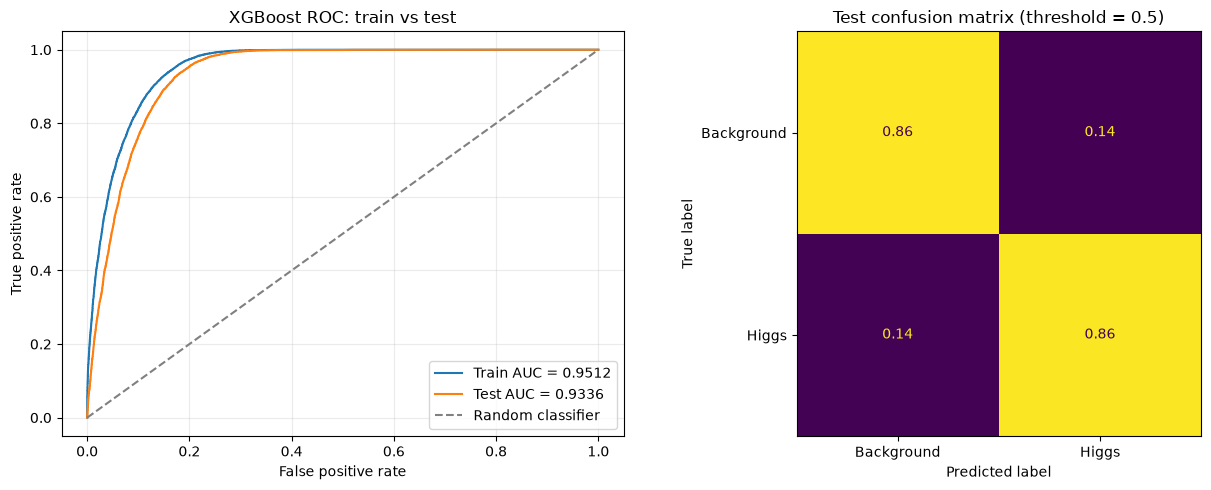

Train ROC-AUC (in-sample): 0.9512
Test ROC-AUC:              0.9336


In [28]:
# ROC curves: training vs test
from sklearn.metrics import roc_curve, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay

# Scores on training events (in-sample) and held-out test events
train_prob = xgb_model.predict_proba(X_train)[:, 1]
test_prob = xgb_model.predict_proba(X_test)[:, 1]

fpr_train, tpr_train, _ = roc_curve(y_train, train_prob)
fpr_test, tpr_test, _ = roc_curve(y_test, test_prob)

auc_train = roc_auc_score(y_train, train_prob)
auc_test = roc_auc_score(y_test, test_prob)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(fpr_train, tpr_train,
             label=f"Train AUC = {auc_train:.4f}")
axes[0].plot(fpr_test, tpr_test,
             label=f"Test AUC = {auc_test:.4f}")
axes[0].plot([0, 1], [0, 1], "--", color="gray",
             label="Random classifier")
axes[0].set_xlabel("False positive rate")
axes[0].set_ylabel("True positive rate")
axes[0].set_title("XGBoost ROC: train vs test")
axes[0].legend()
axes[0].grid(alpha=0.25)

test_pred = (test_prob >= 0.5).astype(int)
cm = confusion_matrix(y_test, test_pred, labels=[0, 1],
                      normalize="true")
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Background", "Higgs"]
)
disp.plot(ax=axes[1], values_format=".2f", colorbar=False)
axes[1].set_title("Test confusion matrix (threshold = 0.5)")

plt.tight_layout()
plt.show()

print(f"Train ROC-AUC (in-sample): {auc_train:.4f}")
print(f"Test ROC-AUC:              {auc_test:.4f}")

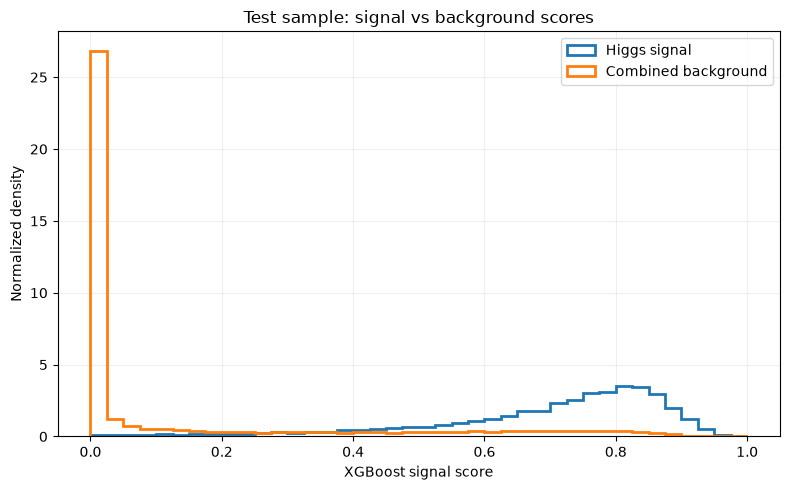

Test Higgs vs combined background score: KS D = 0.7553, p-value = 0, n1 = 11,947, n2 = 26,657


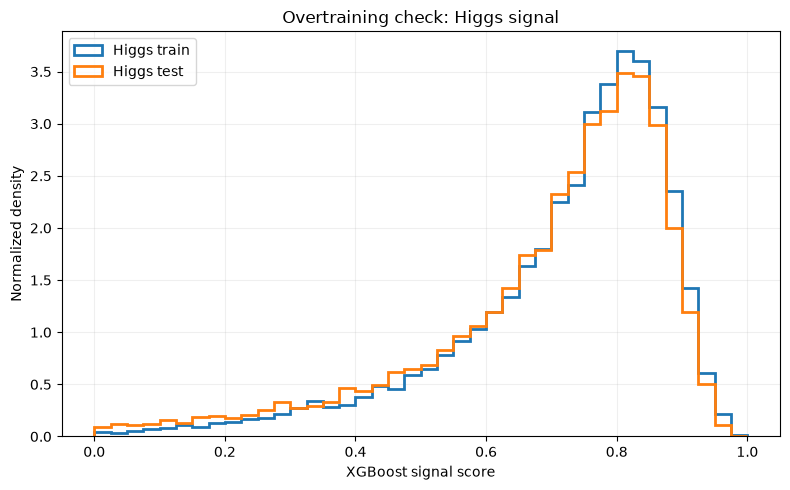

Higgs train vs test scores: KS D = 0.0436, p-value = 2.249e-10, n1 = 12,062, n2 = 11,947


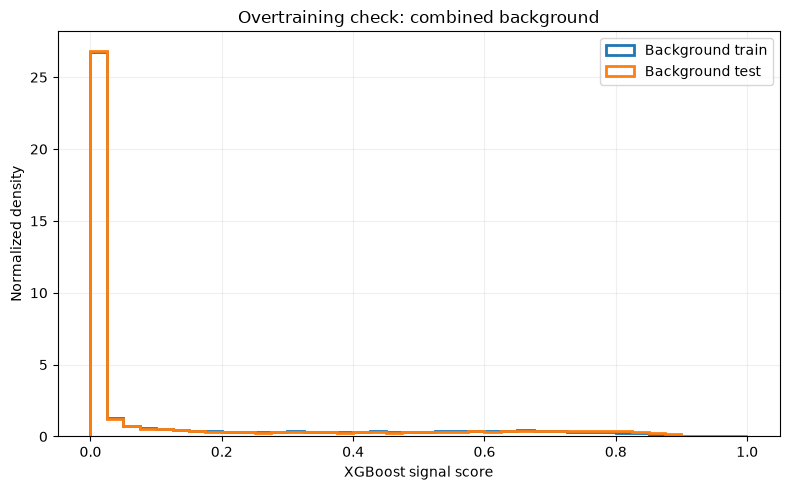

Background train vs test scores: KS D = 0.0170, p-value = 0.0008921, n1 = 26,518, n2 = 26,657


In [29]:
# KS studies of XGBoost classifier scores
from scipy.stats import ks_2samp

# These are already calculated in the ROC cell above:
# train_prob, test_prob

train_scores = train_df[["process", "label"]].copy()
train_scores["score"] = train_prob

test_scores = test_df[["process", "label"]].copy()
test_scores["score"] = test_prob


def ks_report(a, b, name):
    """Print the two-sample KS statistic and p-value."""
    a = np.asarray(a)
    b = np.asarray(b)
    a = a[np.isfinite(a)]
    b = b[np.isfinite(b)]

    if len(a) == 0 or len(b) == 0:
        print(f"{name}: cannot calculate KS; one sample is empty.")
        return

    result = ks_2samp(a, b)
    print(
        f"{name}: KS D = {result.statistic:.4f}, "
        f"p-value = {result.pvalue:.4g}, "
        f"n1 = {len(a):,}, n2 = {len(b):,}"
    )


# Plot 1: signal vs combined background in the test set
sig_test = test_scores.loc[test_scores["label"] == 1, "score"]
bkg_test = test_scores.loc[test_scores["label"] == 0, "score"]

plt.figure(figsize=(8, 5))
plt.hist(sig_test, bins=40, range=(0, 1), density=True,
         histtype="step", linewidth=2, label="Higgs signal")
plt.hist(bkg_test, bins=40, range=(0, 1), density=True,
         histtype="step", linewidth=2, label="Combined background")
plt.xlabel("XGBoost signal score")
plt.ylabel("Normalized density")
plt.title("Test sample: signal vs background scores")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

ks_report(sig_test, bkg_test,
          "Test Higgs vs combined background score")


# Plot 2: training vs test scores for Higgs signal
sig_train = train_scores.loc[train_scores["label"] == 1, "score"]
sig_test = test_scores.loc[test_scores["label"] == 1, "score"]

plt.figure(figsize=(8, 5))
plt.hist(sig_train, bins=40, range=(0, 1), density=True,
         histtype="step", linewidth=2, label="Higgs train")
plt.hist(sig_test, bins=40, range=(0, 1), density=True,
         histtype="step", linewidth=2, label="Higgs test")
plt.xlabel("XGBoost signal score")
plt.ylabel("Normalized density")
plt.title("Overtraining check: Higgs signal")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

ks_report(sig_train, sig_test, "Higgs train vs test scores")


# Plot 3: training vs test scores for combined background
bkg_train = train_scores.loc[train_scores["label"] == 0, "score"]
bkg_test = test_scores.loc[test_scores["label"] == 0, "score"]

plt.figure(figsize=(8, 5))
plt.hist(bkg_train, bins=40, range=(0, 1), density=True,
         histtype="step", linewidth=2, label="Background train")
plt.hist(bkg_test, bins=40, range=(0, 1), density=True,
         histtype="step", linewidth=2, label="Background test")
plt.xlabel("XGBoost signal score")
plt.ylabel("Normalized density")
plt.title("Overtraining check: combined background")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

ks_report(bkg_train, bkg_test, "Background train vs test scores")

\(D\) is the maximum difference between the two empirical cumulative distributions. A smaller \(D\) means the distributions are closer. The p-value assesses compatibility under the KS test assumptions; with large samples, even small differences can yield small p-values, so interpret the statistic and plots together.



# XGBoost gain importance

,gain
mll,339.373444
mth,28.882881
ptll,18.197203
mtw2,12.759423
Jet_pt,12.080262
mjj,11.618522
Jet_jetId,10.253642
PuppiMET_pt,9.979219
nJet,9.935772
dphill,9.052898


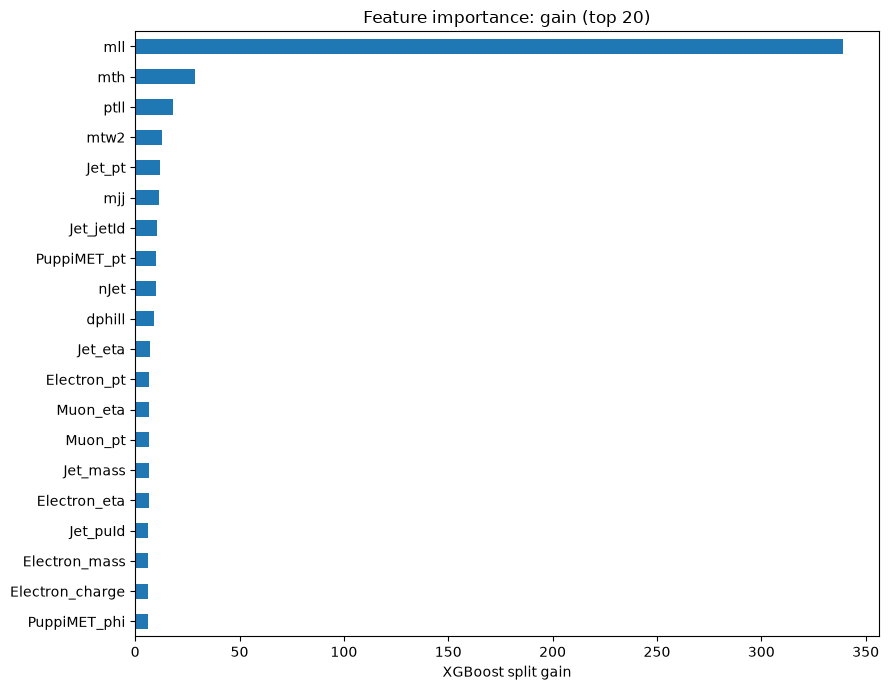

In [30]:
booster = xgb_model.get_booster()
gain_dict = booster.get_score(importance_type="gain")
gain_importance = pd.Series({feature: gain_dict.get(feature, 0.0) for feature in feature_cols}, name="gain").sort_values(ascending=False)
display(gain_importance.to_frame())
ax = gain_importance.head(20).sort_values().plot(kind="barh", figsize=(9, 7))
ax.set_xlabel("XGBoost split gain")
ax.set_title("Feature importance: gain (top 20)")
plt.tight_layout()
plt.show()

# Permutation importance on he;d-out evaluation sample

,mean_auc_drop
mll,0.372635
mth,0.019630
ptll,0.005147
Jet_pt,0.003945
PuppiMET_pt,0.002092
mtw2,0.002059
mjj,0.001177
nJet,0.000988
Muon_eta,0.000690
Jet_eta,0.000506


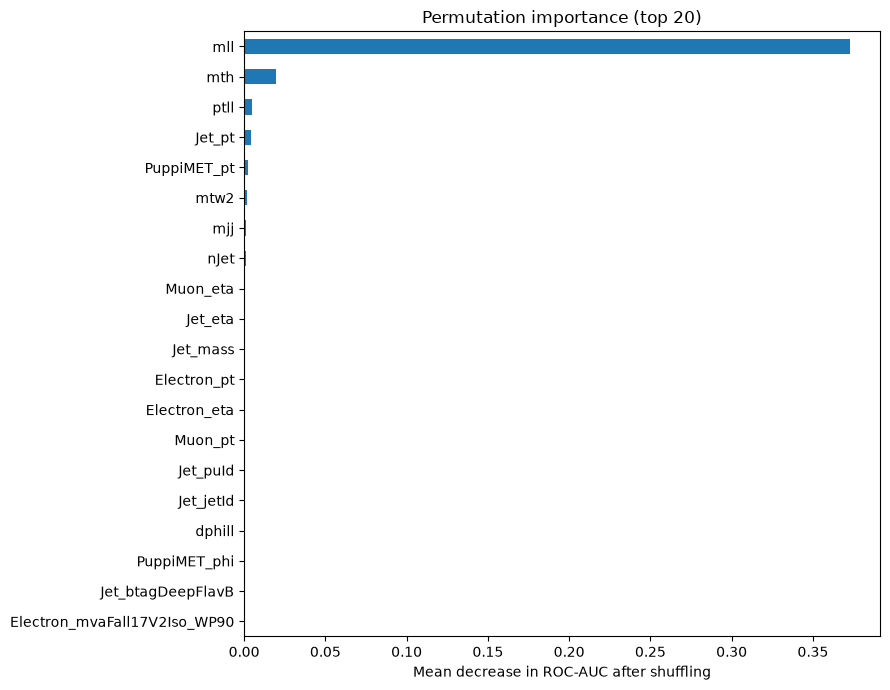

In [31]:
rng = np.random.default_rng(RANDOM_STATE)
perm_n = min(15000, len(X_test))
perm_idx = rng.choice(len(X_test), size=perm_n, replace=False)
perm = permutation_importance(
    xgb_model, X_test.iloc[perm_idx], y_test[perm_idx],
    scoring="roc_auc", n_repeats=3, random_state=RANDOM_STATE, n_jobs=-1
)
perm_importance = pd.Series(perm.importances_mean, index=feature_cols, name="mean_auc_drop").sort_values(ascending=False)
display(perm_importance.to_frame())
ax = perm_importance.head(20).sort_values().plot(kind="barh", figsize=(9, 7))
ax.set_xlabel("Mean decrease in ROC-AUC after shuffling")
ax.set_title("Permutation importance (top 20)")
plt.tight_layout()
plt.show()

# per background feature importance

To keep this manageable, it samples up to 5,000 events per class for each comparison


Higgs vs WW
Higgs events available: 11,947
WW events available: 17,885
Pairwise ROC-AUC on this balanced subset: 0.9025


,Higgs_vs_WW
mll,0.315030
mth,0.027634
Jet_pt,0.005020
ptll,0.003497
mtw2,0.003199
PuppiMET_pt,0.002879
nJet,0.001972
mjj,0.001582
Muon_eta,0.001456
Electron_eta,0.001353


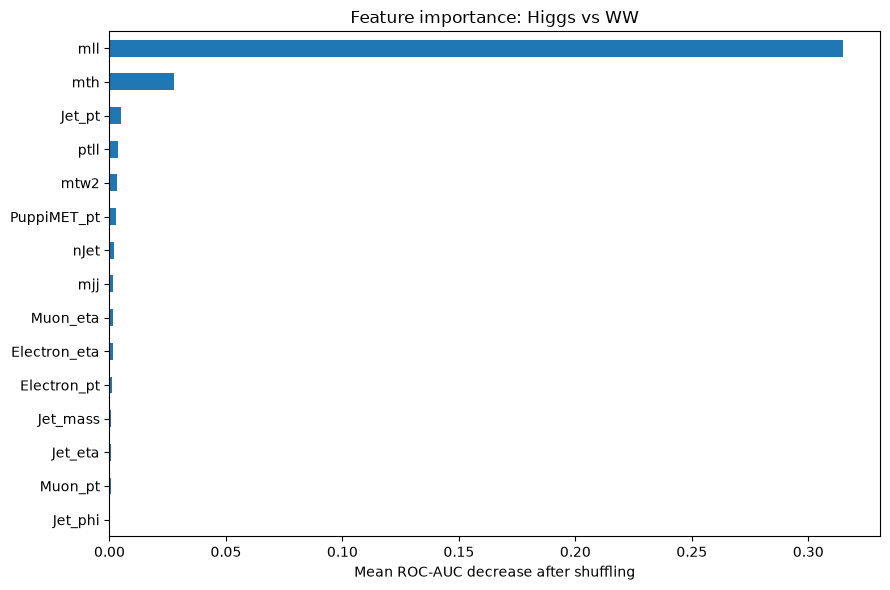


Higgs vs Top
Higgs events available: 11,947
Top events available: 58
Pairwise ROC-AUC on this balanced subset: 0.7658


,Higgs_vs_Top
mll,0.361375
Jet_pt,0.027249
Muon_eta,0.015557
ptll,0.014566
Jet_jetId,0.009116
Muon_phi,0.007233
Electron_phi,0.006540
dphill,0.006143
Muon_pfRelIso04_all,0.005846
Electron_pt,0.004855


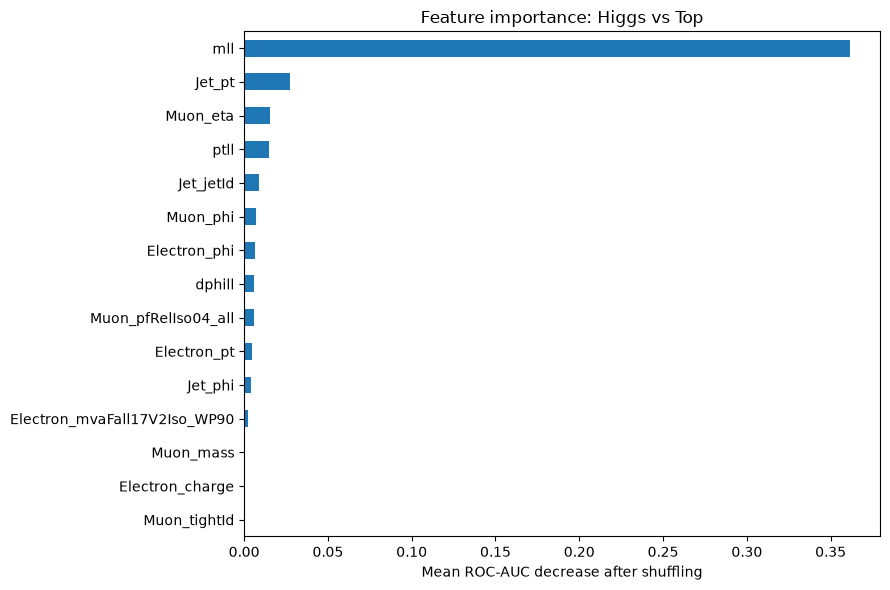


Higgs vs DY
Higgs events available: 11,947
DY events available: 8,714
Pairwise ROC-AUC on this balanced subset: 0.9936


,Higgs_vs_DY
mll,0.412922
ptll,0.003295
mth,0.000308
Jet_pt,0.000301
PuppiMET_pt,0.000260
Muon_pt,0.000223
dphill,0.000213
Muon_eta,0.000160
Jet_puId,0.000126
Muon_pfRelIso04_all,0.000120


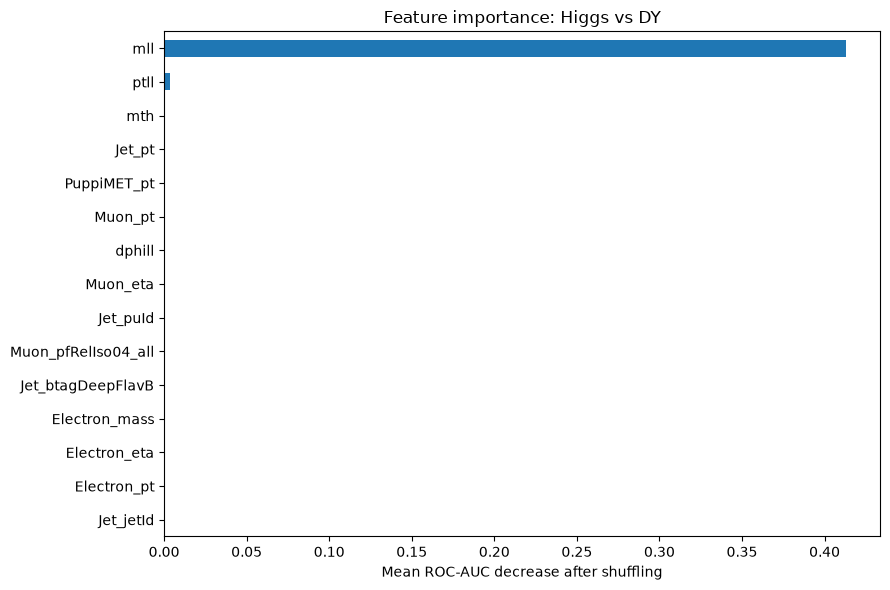

,Higgs_vs_WW,Higgs_vs_Top,Higgs_vs_DY
mll,0.315030,0.361375,0.412922
mth,0.027634,-0.043302,0.000308
Jet_pt,0.005020,0.027249,0.000301
ptll,0.003497,0.014566,0.003295
mtw2,0.003199,-0.001387,-0.000214
PuppiMET_pt,0.002879,-0.010602,0.000260
nJet,0.001972,-0.022295,-0.000086
mjj,0.001582,-0.017440,-0.000092
Muon_eta,0.001456,0.015557,0.000160
Electron_eta,0.001353,-0.000495,0.000094


In [32]:
# Per-background permutation importance:
# Higgs vs WW, Higgs vs Top, Higgs vs DY

from sklearn.inspection import permutation_importance

BACKGROUND_PROCESSES = ["WW", "Top", "DY"]
MAX_EVENTS_PER_CLASS = 5000
N_REPEATS = 3

pairwise_importance = {}

for background in BACKGROUND_PROCESSES:
    print(f"\n{'=' * 60}")
    print(f"Higgs vs {background}")
    print(f"{'=' * 60}")

    # Use only Higgs and the selected background from the TEST files.
    pair_df = test_df[
        test_df["process"].isin(["Higgs", background])
    ].copy()

    n_higgs = int((pair_df["process"] == "Higgs").sum())
    n_background = int((pair_df["process"] == background).sum())

    print(f"Higgs events available: {n_higgs:,}")
    print(f"{background} events available: {n_background:,}")

    if n_higgs < 2 or n_background < 2:
        print("Skipping: too few events for a meaningful comparison.")
        continue

    # Use equal-sized samples so the comparison is not dominated
    # by the larger class. This is a diagnostic subset.
    n_each = min(MAX_EVENTS_PER_CLASS, n_higgs, n_background)

    higgs_sample = pair_df[pair_df["process"] == "Higgs"].sample(
        n=n_each, random_state=RANDOM_STATE
    )
    bkg_sample = pair_df[pair_df["process"] == background].sample(
        n=n_each, random_state=RANDOM_STATE
    )

    pair_sample = pd.concat(
        [higgs_sample, bkg_sample], ignore_index=True
    ).sample(frac=1, random_state=RANDOM_STATE)

    X_pair = (
        pair_sample[feature_cols]
        .replace([np.inf, -np.inf], np.nan)
    )
    y_pair = pair_sample["label"].astype(int).to_numpy()

    # Evaluate the already-trained model; do not refit it here.
    pair_auc = roc_auc_score(
        y_pair, xgb_model.predict_proba(X_pair)[:, 1]
    )
    print(f"Pairwise ROC-AUC on this balanced subset: {pair_auc:.4f}")

    result = permutation_importance(
        xgb_model,
        X_pair,
        y_pair,
        scoring="roc_auc",
        n_repeats=N_REPEATS,
        random_state=RANDOM_STATE,
        n_jobs=1,
    )

    importance = pd.Series(
        result.importances_mean,
        index=feature_cols,
        name=f"Higgs_vs_{background}",
    ).sort_values(ascending=False)

    pairwise_importance[background] = importance

    display(importance.head(15).to_frame())

    ax = importance.head(15).sort_values().plot(
        kind="barh", figsize=(9, 6)
    )
    ax.set_xlabel("Mean ROC-AUC decrease after shuffling")
    ax.set_title(f"Feature importance: Higgs vs {background}")
    plt.tight_layout()
    plt.show()


# Compare the top features across backgrounds in one table.
if pairwise_importance:
    importance_comparison = pd.concat(
        pairwise_importance.values(), axis=1
    ).fillna(0.0)

    display(
        importance_comparison.sort_values(
            by=list(importance_comparison.columns),
            ascending=False,
        ).head(20)
    )

vs ww - dilepton invariant mass is doing most of the discriminating work in this comparison.

vs top - Isolation appears in this ranking, but it contributes much less than mll in the displayed result.

vs dy - again mll - overwhelmingly dominant

(The Top sample contains only 58 selected test events. That is far too small to draw strong conclusions about which variables distinguish Higgs from Top. There is also a methodological limitation: the code evaluates the same combined-background model on pairwise subsets. It does not train a dedicated Higgs-versus-WW, Higgs-versus-Top or Higgs-versus-DY classifier. Therefore, the rankings describe how the existing model behaves on those subsets.)

In [33]:
# Validate selected event counts, especially the Top sample

for split_name, frame in [
    ("Training", train_df),
    ("Test/evaluation", test_df),
]:
    print(f"\n{split_name} sample")

    counts = (
        frame.groupby("process")
        .agg(
            selected_events=("label", "size"),
            higgs_label_count=("label", "sum"),
        )
        .sort_index()
    )
    counts["fraction_of_selected_sample"] = (
        counts["selected_events"] / len(frame)
    )

    display(counts)

    top_count = int((frame["process"] == "Top").sum())
    print(f"Top selected events: {top_count:,}")

    if top_count < 100:
        print(
            "WARNING: very low Top yield after selection. "
            "Check the Top ROOT file's contents, its cutflow, "
            "branch interpretation, and selection efficiency "
            "before trusting Top-related conclusions."
        )

# Confirm the requested 29 features are present.
print("\nIsolation and identification features:")
for feature in [
    "Electron_mvaFall17V2Iso_WP90",
    "Muon_pfRelIso04_all",
    "Muon_tightId",
]:
    print(
        f"{feature}: "
        f"in feature list = {feature in feature_cols}; "
        f"in training dataframe = {feature in train_df.columns}; "
        f"in test dataframe = {feature in test_df.columns}"
    )


Training sample


,selected_events,higgs_label_count,fraction_of_selected_sample
process,,,
DY,9001,0,0.233307
Higgs,12062,12062,0.312649
Top,67,0,0.001737
WW,17450,0,0.452307


Top selected events: 67

Test/evaluation sample


,selected_events,higgs_label_count,fraction_of_selected_sample
process,,,
DY,8714,0,0.225728
Higgs,11947,11947,0.309476
Top,58,0,0.001502
WW,17885,0,0.463294


Top selected events: 58

Isolation and identification features:
Electron_mvaFall17V2Iso_WP90: in feature list = True; in training dataframe = True; in test dataframe = True
Muon_pfRelIso04_all: in feature list = True; in training dataframe = True; in test dataframe = True
Muon_tightId: in feature list = True; in training dataframe = True; in test dataframe = True


# Correlation among important features

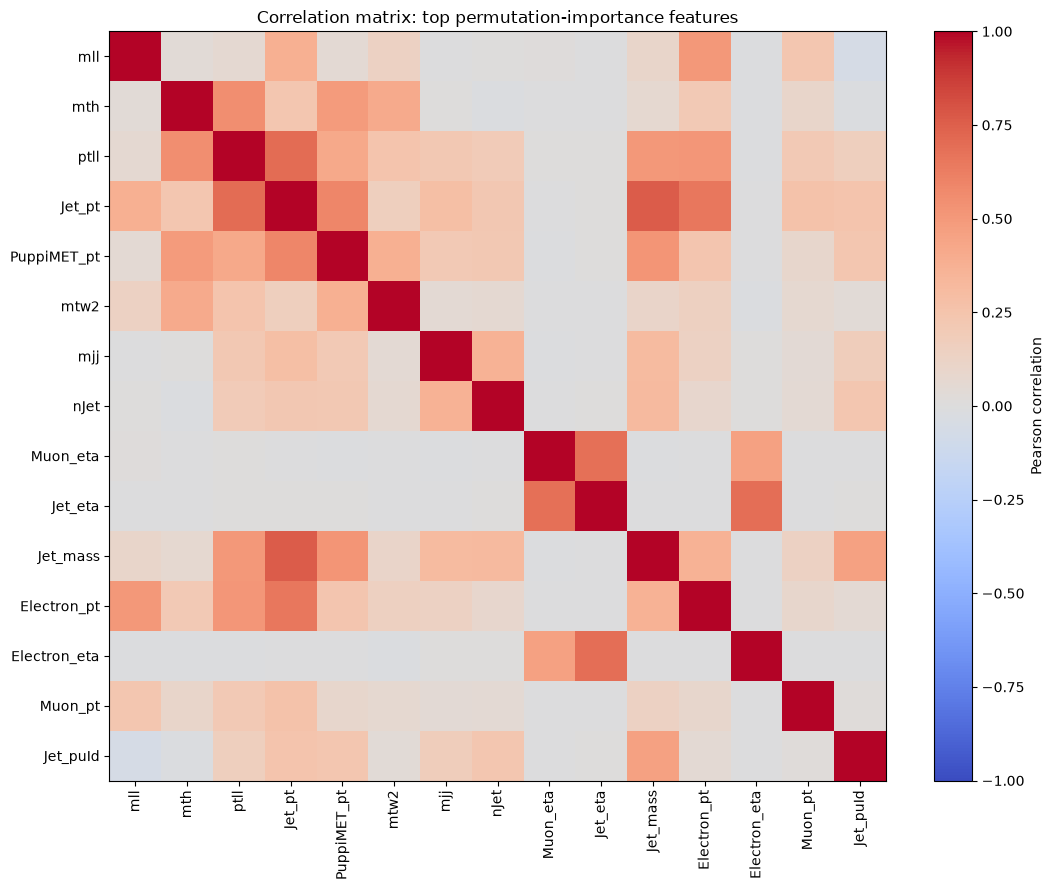

In [34]:
top_corr_features = perm_importance.head(min(15, len(perm_importance))).index.tolist()
corr = train_df[top_corr_features].corr()
fig, ax = plt.subplots(figsize=(11, 9))
im = ax.imshow(corr, vmin=-1, vmax=1, cmap="coolwarm", aspect="auto")
ax.set_xticks(range(len(top_corr_features)))
ax.set_xticklabels(top_corr_features, rotation=90)
ax.set_yticks(range(len(top_corr_features)))
ax.set_yticklabels(top_corr_features)
ax.set_title("Correlation matrix: top permutation-importance features")
fig.colorbar(im, ax=ax, label="Pearson correlation")
plt.tight_layout()
plt.show()

# Random Forest baseline

The primary XGBoost model uses all 29 input columns. For Random Forest, columns that are entirely missing in the training sample are excluded from the imputer/model because a median cannot be estimated for an all-missing column; the retained feature list is printed.

In [35]:
rf_features = [c for c in feature_cols if X_train[c].notna().any()]
if not rf_features:
    raise ValueError("No non-empty features are available for Random Forest.")
rf_pipeline = make_pipeline(
    SimpleImputer(strategy="median", add_indicator=True),
    RandomForestClassifier(
        n_estimators=300, min_samples_leaf=5, max_features="sqrt",
        class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1
    )
)
rf_pipeline.fit(X_train[rf_features], y_train)
rf_prob = rf_pipeline.predict_proba(X_test[rf_features])[:, 1]
rf_auc = roc_auc_score(y_test, rf_prob)
print("Random Forest input features:", len(rf_features), "of 29")
print(f"Random Forest ROC-AUC: {rf_auc:.4f}")
print(f"XGBoost ROC-AUC:       {xgb_auc:.4f}")

Random Forest input features: 29 of 29
Random Forest ROC-AUC: 0.9301
XGBoost ROC-AUC:       0.9336


# Optional 1D CNN comparison

a 1D CNN on tabular variables assumes an ordering among features, which is not inherently physical. The cell gracefully skips if TensorFlow is unavailable. Entirely missing training columns are excluded from the CNN input.

In [36]:
try:
    import tensorflow as tf
    from tensorflow import keras
    from tensorflow.keras import layers
    TF_AVAILABLE = True
    print("TensorFlow:", tf.__version__)
except Exception as exc:
    TF_AVAILABLE = False
    print("TensorFlow unavailable; skipping CNN:", repr(exc))

if TF_AVAILABLE:
    cnn_features = [c for c in feature_cols if X_train[c].notna().any()]
    imputer = SimpleImputer(strategy="median")
    scaler = StandardScaler()
    Xtr_imp = imputer.fit_transform(X_train[cnn_features])
    Xte_imp = imputer.transform(X_test[cnn_features])
    Xtr_scaled = scaler.fit_transform(Xtr_imp).astype("float32")
    Xte_scaled = scaler.transform(Xte_imp).astype("float32")
    Xtr_cnn = Xtr_scaled[..., np.newaxis]
    Xte_cnn = Xte_scaled[..., np.newaxis]

    tf.keras.utils.set_random_seed(RANDOM_STATE)
    cnn_model = keras.Sequential([
        layers.Input(shape=(Xtr_cnn.shape[1], 1)),
        layers.Conv1D(32, kernel_size=3, padding="same", activation="relu"),
        layers.BatchNormalization(),
        layers.Conv1D(64, kernel_size=3, padding="same", activation="relu"),
        layers.GlobalMaxPooling1D(),
        layers.Dense(64, activation="relu"),
        layers.Dropout(0.25),
        layers.Dense(1, activation="sigmoid"),
    ])
    cnn_model.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3),
                      loss="binary_crossentropy",
                      metrics=[keras.metrics.AUC(name="auc"), "accuracy"])
    callbacks = [keras.callbacks.EarlyStopping(monitor="val_auc", mode="max", patience=4, restore_best_weights=True)]
    history = cnn_model.fit(
        Xtr_cnn, y_train, validation_split=0.15, epochs=20,
        batch_size=512, callbacks=callbacks, verbose=1
    )
    cnn_prob = cnn_model.predict(Xte_cnn, batch_size=2048, verbose=0).ravel()
    cnn_auc = roc_auc_score(y_test, cnn_prob)
    print(f"CNN ROC-AUC: {cnn_auc:.4f}")
    plt.figure(figsize=(7, 5))
    plt.plot(*roc_curve(y_test, xgb_prob)[:2], label=f"XGBoost (AUC={xgb_auc:.3f})", linewidth=2)
    plt.plot(*roc_curve(y_test, cnn_prob)[:2], label=f"1D CNN (AUC={cnn_auc:.3f})", linewidth=2)
    plt.plot([0, 1], [0, 1], "--", color="gray")
    plt.xlabel("False positive rate")
    plt.ylabel("True positive rate")
    plt.title("XGBoost vs 1D CNN")
    plt.legend()
    plt.grid(alpha=0.25)
    plt.tight_layout()
    plt.show()

TensorFlow unavailable; skipping CNN: ModuleNotFoundError("No module named 'tensorflow'")


In [37]:
model_path = Path("hww_xgboost_model.json")
xgb_model.save_model(model_path)
feature_path = Path("hww_model_features.json")
feature_path.write_text(json.dumps({
    "features": feature_cols,
    "n_features": len(feature_cols),
    "physics_selection": {
        "exactly_two_selected_e_or_mu": True,
        "electron_pt_loose_min_GeV": LEPTON_LOOSE_PT_MIN,
        "electron_abs_eta_max": ELECTRON_ABS_ETA_MAX,
        "electron_id": "Electron_mvaFall17V2Iso_WP90 == 1",
        "muon_abs_eta_max": MUON_ABS_ETA_MAX,
        "muon_id": "Muon_tightId == 1",
        "muon_rel_iso_max": MUON_REL_ISO_MAX,
        "leading_lepton_pt_min_GeV": LEADING_LEPTON_PT_MIN,
        "subleading_lepton_pt_min_GeV": SUBLEADING_LEPTON_PT_MIN,
        "opposite_sign": True,
        "mll_min_GeV": DILEPTON_MASS_MIN,
        "PuppiMET_pt_min_GeV": PUPPI_MET_PT_MIN,
    },
    "evaluation_source": "dedicated test files" if USE_FILE_TEST_SET else "stratified holdout from training files",
}, indent=2))
print("Saved model:", model_path.resolve())
print("Saved feature/selection metadata:", feature_path.resolve())

Saved model: /home/jovyan/hsf-india-bvcoe-2026/hww_xgboost_model.json
Saved feature/selection metadata: /home/jovyan/hsf-india-bvcoe-2026/hww_model_features.json
